# Early Prediction of Student Dropout — Part 1: Initial Comparison

**LIS4032 Selected Topics 1 — Machine Learning, UDLAP, Fall 2026** · Dr. Edwin Montes Orozco

**Team XX**

| Member | Student ID |
|---|---|
| Member Name 1 | 000000 |
| Member Name 2 | 000000 |
| Member Name 3 | 000000 |

**Dataset:** *Predict Students' Dropout and Academic Success*, UCI Machine Learning Repository (Realinho et al., 2022), CC BY 4.0, https://archive.ics.uci.edu/dataset/697 — file `data.csv` saved in `data/`.

**Notebook structure:** 1. Problem · 2. Data · 3. Splits · 4. Preparation · 5. Baseline · 6. Models · 7. Comparison · 8. Conclusions

**Reproducibility:** every random process uses `SEED = 42`. Run with *Restart & Run All*.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
DATA_PATH = os.path.join("data", "data.csv")
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
pd.set_option("display.max_columns", 50)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | numpy 2.5.3


## 1. Problem

Dropping out of university is costly for students, families and institutions, and part of it could be prevented with early support.

**Question.** At the end of a student's **first semester**, can we predict whether the student will end up as *Dropout*, *Enrolled* (still studying at the end of the normal duration of the program) or *Graduate*?

- **Intended user:** academic tutoring and student-support offices, to decide which students to contact first (tutoring, counseling, financial aid). The model supports prioritization; it does not make decisions about students.
- **Unit of analysis:** one row = one undergraduate student, described at enrollment and after the first semester.
- **Target:** `target` with three classes (Dropout, Enrolled, Graduate).
- **Task type:** supervised multiclass classification.
- **Primary metric (defined before looking at results):** **macro F1** on validation, because every class gets the same weight and accuracy would hide a model that ignores the minority class *Enrolled*. We also report accuracy, macro precision, macro recall, the confusion matrix and the F1 / recall of *Dropout*, the class the support office cares about most.
- **Moment of prediction:** end of the 1st semester. Any variable known only later is excluded (Section 2.4).

## 2. Data

### 2.1 Loading

In [2]:
raw = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")  # the file starts with a BOM
print("Shape:", raw.shape)
# Column names in the original file contain stray tabs and spaces; we normalise them to snake_case
def snake(c):
    c = c.strip().lower()
    for a, b in [("'", ""), ("(", ""), (")", ""), ("/", "_"), (" ", "_")]:
        c = c.replace(a, b)
    return c.replace("nacionality", "nationality")  # typo in the original file
df = raw.rename(columns=snake).copy()
# The file has no identifier: we create one from the original row number (0-based) so splits can be rebuilt
df.insert(0, "student_id", np.arange(len(df)))
df.head()

Shape: (4424, 37)


,student_id,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### 2.2 Data dictionary

Meanings follow the UCI documentation (Realinho et al., 2022). Several variables are **numeric codes of categories** (e.g. `course`, `application_mode`, parents' occupation): they look numeric, but they are nominal and will be one-hot encoded. The dictionary is saved as `diccionario_variables.csv`.

In [3]:
D = [  # name, meaning, type, unit / values, role
("student_id","Row identifier created from the original row number","identifier","integer","id (not a predictor)"),
("marital_status","Marital status at enrollment (1 single, 2 married, 3 widower, 4 divorced, 5 de facto union, 6 legally separated)","categorical (nominal, coded)","code 1-6","predictor"),
("application_mode","Application mode / admission route (e.g. 1st phase general contingent, over 23 years old, transfer)","categorical (nominal, coded)","code","predictor"),
("application_order","Preference order of the program in the application (0 = first choice ... 9 = last)","numeric (ordinal)","0-9","predictor"),
("course","Undergraduate program (e.g. 9500 Nursing, 9147 Management, 9119 Informatics Engineering)","categorical (nominal, coded)","code","predictor"),
("daytime_evening_attendance","Attendance schedule","binary","1 daytime, 0 evening","predictor"),
("previous_qualification","Highest qualification obtained before enrollment","categorical (nominal, coded)","code","predictor"),
("previous_qualification_grade","Grade of the previous qualification","numeric (continuous)","points, 0-200","predictor"),
("nationality","Nationality of the student","categorical (nominal, coded)","code","predictor"),
("mothers_qualification","Mother's highest education level","categorical (nominal, coded)","code","predictor"),
("fathers_qualification","Father's highest education level","categorical (nominal, coded)","code","predictor"),
("mothers_occupation","Mother's occupation","categorical (nominal, coded)","code","predictor"),
("fathers_occupation","Father's occupation","categorical (nominal, coded)","code","predictor"),
("admission_grade","Admission grade","numeric (continuous)","points, 0-200","predictor"),
("displaced","Student lives away from home to study","binary","1 yes, 0 no","predictor"),
("educational_special_needs","Student has educational special needs","binary","1 yes, 0 no","predictor"),
("debtor","Student owes money to the institution","binary","1 yes, 0 no","predictor"),
("tuition_fees_up_to_date","Tuition fees paid up to date","binary","1 yes, 0 no","predictor"),
("gender","Gender","binary","1 male, 0 female","predictor"),
("scholarship_holder","Student has a scholarship","binary","1 yes, 0 no","predictor"),
("age_at_enrollment","Age at enrollment","numeric (discrete)","years","predictor"),
("international","International student","binary","1 yes, 0 no","predictor"),
("curricular_units_1st_sem_credited","Courses credited (recognised from previous studies) in the 1st semester","numeric (discrete)","number of courses","predictor"),
("curricular_units_1st_sem_enrolled","Courses enrolled in the 1st semester","numeric (discrete)","number of courses","predictor"),
("curricular_units_1st_sem_evaluations","Evaluations (exams) taken in the 1st semester","numeric (discrete)","number of evaluations","predictor"),
("curricular_units_1st_sem_approved","Courses passed in the 1st semester","numeric (discrete)","number of courses","predictor"),
("curricular_units_1st_sem_grade","Average grade in the 1st semester","numeric (continuous)","points, 0-20","predictor"),
("curricular_units_1st_sem_without_evaluations","Courses without any evaluation in the 1st semester","numeric (discrete)","number of courses","predictor"),
("curricular_units_2nd_sem_credited","Courses credited in the 2nd semester","numeric (discrete)","number of courses","excluded (known after the moment of prediction)"),
("curricular_units_2nd_sem_enrolled","Courses enrolled in the 2nd semester","numeric (discrete)","number of courses","excluded (known after the moment of prediction)"),
("curricular_units_2nd_sem_evaluations","Evaluations taken in the 2nd semester","numeric (discrete)","number of evaluations","excluded (known after the moment of prediction)"),
("curricular_units_2nd_sem_approved","Courses passed in the 2nd semester","numeric (discrete)","number of courses","excluded (known after the moment of prediction)"),
("curricular_units_2nd_sem_grade","Average grade in the 2nd semester","numeric (continuous)","points, 0-20","excluded (known after the moment of prediction)"),
("curricular_units_2nd_sem_without_evaluations","Courses without evaluation in the 2nd semester","numeric (discrete)","number of courses","excluded (known after the moment of prediction)"),
("unemployment_rate","National unemployment rate in the year of enrollment","numeric (continuous)","%","predictor"),
("inflation_rate","National inflation rate in the year of enrollment","numeric (continuous)","%","predictor"),
("gdp","National GDP growth in the year of enrollment","numeric (continuous)","% change","predictor"),
("target","Academic status at the end of the normal duration of the program","categorical (target)","Dropout / Enrolled / Graduate","target"),
]
dic = pd.DataFrame(D, columns=["variable", "meaning", "type", "unit_or_values", "role"])
assert set(dic.variable) == set(df.columns), set(dic.variable) ^ set(df.columns)
dic.to_csv("diccionario_variables.csv", index=False)
dic

,variable,meaning,type,unit_or_values,role
0,student_id,Row identifier created from the original row n...,identifier,integer,id (not a predictor)
1,marital_status,"Marital status at enrollment (1 single, 2 marr...","categorical (nominal, coded)",code 1-6,predictor
2,application_mode,Application mode / admission route (e.g. 1st p...,"categorical (nominal, coded)",code,predictor
3,application_order,Preference order of the program in the applica...,numeric (ordinal),0-9,predictor
4,course,"Undergraduate program (e.g. 9500 Nursing, 9147...","categorical (nominal, coded)",code,predictor
5,daytime_evening_attendance,Attendance schedule,binary,"1 daytime, 0 evening",predictor
6,previous_qualification,Highest qualification obtained before enrollment,"categorical (nominal, coded)",code,predictor
7,previous_qualification_grade,Grade of the previous qualification,numeric (continuous),"points, 0-200",predictor
8,nationality,Nationality of the student,"categorical (nominal, coded)",code,predictor
9,mothers_qualification,Mother's highest education level,"categorical (nominal, coded)",code,predictor


### 2.3 Data quality: types, missing values, duplicates, invalid values and target

In [4]:
print("Data types:\n", df.dtypes.value_counts(), "\n")
print("Missing values (total):", int(df.isna().sum().sum()))
print("Duplicated rows (ignoring student_id):", int(df.drop(columns="student_id").duplicated().sum()))

checks = {
    "approved > enrolled (1st sem)": (df.curricular_units_1st_sem_approved > df.curricular_units_1st_sem_enrolled).sum(),
    "grade > 0 but 0 approved (1st sem)": ((df.curricular_units_1st_sem_grade > 0) & (df.curricular_units_1st_sem_approved == 0)).sum(),
    "grade outside 0-20 (1st sem)": (~df.curricular_units_1st_sem_grade.between(0, 20)).sum(),
    "admission/previous grade outside 0-200": (~df.admission_grade.between(0, 200) | ~df.previous_qualification_grade.between(0, 200)).sum(),
    "age < 15 or > 80": (~df.age_at_enrollment.between(15, 80)).sum(),
    "0 courses enrolled (1st sem)": (df.curricular_units_1st_sem_enrolled == 0).sum(),
}
pd.Series(checks, name="rows").to_frame()

Data types:
 int64      30
float64     7
str         1
Name: count, dtype: int64 

Missing values (total): 0
Duplicated rows (ignoring student_id): 0


,rows
approved > enrolled (1st sem),0
grade > 0 but 0 approved (1st sem),0
grade outside 0-20 (1st sem),0
admission/previous grade outside 0-200,0
age < 15 or > 80,0
0 courses enrolled (1st sem),180


          count  proportion
target                     
Graduate   2209       0.499
Dropout    1421       0.321
Enrolled    794       0.179


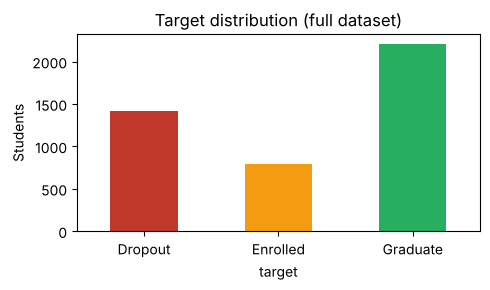

In [5]:
tgt = pd.concat([df.target.value_counts(), df.target.value_counts(normalize=True).round(3)],
                axis=1, keys=["count", "proportion"])
print(tgt)
ax = df.target.value_counts().reindex(["Dropout", "Enrolled", "Graduate"]).plot.bar(
    color=["#c0392b", "#f39c12", "#27ae60"], rot=0, figsize=(5, 3))
ax.set_ylabel("Students"); ax.set_title("Target distribution (full dataset)")
plt.tight_layout(); plt.savefig("figures/target_distribution.png", dpi=150); plt.show()

### 2.4 Leakage and excluded variables

- `student_id` is an identifier with no predictive value: it is kept only to build `particiones.csv`.
- The six **2nd-semester variables** are excluded. They are only known after the moment of prediction, and they almost give the answer away (a student who passes no courses in the 2nd semester has usually already dropped out). Keeping them would give an optimistic model that could not be used at the end of the 1st semester.
- The macroeconomic variables (`unemployment_rate`, `inflation_rate`, `gdp`) refer to the year of enrollment, so they are known in time. They only take a few distinct values (one per cohort), which we keep in mind as a limitation.

In [6]:
ID, TARGET = "student_id", "target"
LEAK = [c for c in df.columns if c.startswith("curricular_units_2nd_sem")]
CAT = ["marital_status", "application_mode", "course", "previous_qualification", "nationality",
       "mothers_qualification", "fathers_qualification", "mothers_occupation", "fathers_occupation"]
FEATURES = [c for c in df.columns if c not in [ID, TARGET] + LEAK]
NUM = [c for c in FEATURES if c not in CAT]
print(f"Excluded (leakage): {len(LEAK)} | Predictors: {len(FEATURES)} = {len(NUM)} numeric/binary + {len(CAT)} nominal")
print("Distinct values per nominal variable:\n", df[CAT].nunique().sort_values(ascending=False).to_string())

Excluded (leakage): 6 | Predictors: 30 = 21 numeric/binary + 9 nominal
Distinct values per nominal variable:
 fathers_occupation        46
fathers_qualification     34
mothers_occupation        32
mothers_qualification     29
nationality               21
application_mode          18
previous_qualification    17
course                    17
marital_status             6


## 3. Splits

Each row is a different student and there is no time order in the file, so the observations are treated as independent. We use the reference split **70 % train / 15 % validation / 15 % test**, `random_state=42`, **stratified** by `target` (the smallest class has about 800 students, enough to stratify). The test set is **reserved for Part 2**: no metric is computed on it in this notebook.

In [7]:
X, y = df[[ID] + FEATURES], df[TARGET]
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

part = pd.concat([pd.DataFrame({ID: X_train[ID], "subset": "train"}),
                  pd.DataFrame({ID: X_val[ID], "subset": "validation"}),
                  pd.DataFrame({ID: X_test[ID], "subset": "test"})]).sort_values(ID)
part.to_csv("particiones.csv", index=False)
assert part[ID].is_unique and len(part) == len(df)

summary = pd.DataFrame({s: yy.value_counts(normalize=True).round(3) for s, yy in
                        [("train", y_train), ("validation", y_val), ("test", y_test)]}).T
summary.insert(0, "n", [len(y_train), len(y_val), len(y_test)])
summary

target,n,Graduate,Dropout,Enrolled
train,3096,0.499,0.321,0.180
validation,664,0.500,0.321,0.179
test,664,0.498,0.322,0.179


### 3.1 Exploration on the training set only

After splitting, all the exploration that guides our decisions uses **training data only**.

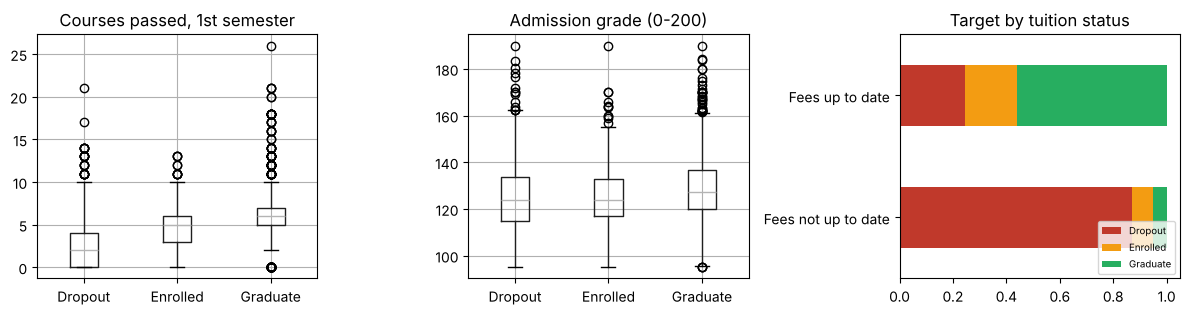

In [8]:
tr = X_train.assign(target=y_train.values)
order = ["Dropout", "Enrolled", "Graduate"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
tr.boxplot(column="curricular_units_1st_sem_approved", by="target", ax=axes[0])
axes[0].set_title("Courses passed, 1st semester"); axes[0].set_xlabel("")
tr.boxplot(column="admission_grade", by="target", ax=axes[1])
axes[1].set_title("Admission grade (0-200)"); axes[1].set_xlabel("")
(pd.crosstab(tr.tuition_fees_up_to_date, tr.target, normalize="index")[order]
   .rename(index={0: "Fees not up to date", 1: "Fees up to date"})
   .plot.barh(stacked=True, ax=axes[2], color=["#c0392b", "#f39c12", "#27ae60"]))
axes[2].set_title("Target by tuition status"); axes[2].set_ylabel(""); axes[2].legend(fontsize=7, loc="lower right")
plt.suptitle(""); plt.tight_layout(); plt.savefig("figures/eda_train.png", dpi=150); plt.show()

In [9]:
print("Mean of selected numeric predictors by class (training set):")
tr.groupby("target")[["age_at_enrollment", "admission_grade", "curricular_units_1st_sem_enrolled",
                      "curricular_units_1st_sem_approved", "curricular_units_1st_sem_grade",
                      "debtor", "scholarship_holder", "tuition_fees_up_to_date"]].mean().round(2)

Mean of selected numeric predictors by class (training set):


,age_at_enrollment,admission_grade,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,debtor,scholarship_holder,tuition_fees_up_to_date
target,,,,,,,,
Dropout,26.10,124.96,5.85,2.58,7.19,0.22,0.10,0.68
Enrolled,22.25,125.31,5.97,4.40,11.20,0.10,0.16,0.95
Graduate,21.71,128.75,6.60,6.17,12.62,0.04,0.39,0.99


In [10]:
rare = {c: int((X_train[c].value_counts() < 10).sum()) for c in CAT}
print("Categories with fewer than 10 training students, per nominal variable:", rare)

Categories with fewer than 10 training students, per nominal variable: {'marital_status': 2, 'application_mode': 5, 'course': 1, 'previous_qualification': 9, 'nationality': 14, 'mothers_qualification': 18, 'fathers_qualification': 21, 'mothers_occupation': 18, 'fathers_occupation': 27}


In [11]:
# Students with 0 courses enrolled and 0 credited in the 1st semester (training set)
z = tr[(tr.curricular_units_1st_sem_enrolled == 0) & (tr.curricular_units_1st_sem_credited == 0)]
print(len(z), "students;", z.target.value_counts().to_dict())

137 students; {'Graduate': 59, 'Dropout': 57, 'Enrolled': 21}


About 4 % of the students have **0 courses enrolled and 0 credited** in the 1st semester, yet a large part of them graduate. This is not physically impossible (for example, students who start in a later semester or follow a different curriculum), but it means that for them the 1st-semester variables carry no information. We keep these rows, because removing them would make the problem look easier than it is, and we flag it as a limitation to review in Part 2.

## 4. Preparation

All transformations are inside a `Pipeline` with a `ColumnTransformer`, so they are **fitted only on the training data** and then applied to validation:

- **Numeric and binary variables:** `SimpleImputer(strategy="median")` (there are no missing values today, but it protects the pipeline against new data) and `StandardScaler`, needed by distance-based and regularised models (KNN, SVC, logistic regression). Trees do not need scaling, but using the same preprocessing keeps the comparison fair.
- **Nominal coded variables:** `SimpleImputer(strategy="most_frequent")` and `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)`. Categories with fewer than 10 training students are grouped into an *infrequent* category, which avoids hundreds of almost-empty columns (for example, rare nationalities or occupations), and categories never seen in training do not break the model.
- **Class imbalance:** no resampling. We use `class_weight="balanced"` in the models that support it (logistic regression, SVC, tree and forest). KNN has no class weights, so it is used as is.

In [12]:
def make_preprocessor():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))])
    return ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

pre = make_preprocessor().fit(X_train[FEATURES])
print("Columns after preprocessing:", pre.transform(X_train[FEATURES]).shape[1])

Columns after preprocessing: 121


## 5. Baseline

Two `DummyClassifier` references: `most_frequent` (always predicts *Graduate*) and `stratified` (predicts at random following the training class proportions). A useful model must clearly beat both in macro F1.

## 6. Models

Five families from the course table, each with **one reasonable initial configuration** (tuning is left for Part 2). All use the same split, the same predictors and the same preprocessing.

| Family | Configuration | Reason |
|---|---|---|
| Logistic regression | `C=1.0`, multinomial, `class_weight="balanced"`, `max_iter=2000` | linear reference, interpretable coefficients |
| KNN | `n_neighbors=15`, `weights="distance"`, Euclidean | $k \approx \sqrt{n_{train}}/4$; distance weights reduce the effect of far neighbours |
| SVC | RBF kernel, `C=1.0`, `gamma="scale"`, `class_weight="balanced"` | non-linear boundary with default margin |
| Decision tree | `max_depth=6`, `min_samples_leaf=20`, `class_weight="balanced"` | depth limited to avoid memorising the training set |
| Random forest | `n_estimators=300`, `min_samples_leaf=2`, `max_features="sqrt"`, `class_weight="balanced"` | bagging of trees reduces variance |

In [13]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Baseline (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic regression": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "SVC (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED),
    "Decision tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, max_features="sqrt",
                                            class_weight="balanced", n_jobs=-1, random_state=SEED),
}
configs = {n: ", ".join(f"{k}={v}" for k, v in m.get_params().items()
                        if k in ["strategy", "C", "class_weight", "n_neighbors", "weights", "kernel", "gamma",
                                 "max_depth", "min_samples_leaf", "n_estimators", "max_features"])
           for n, m in models.items()}

Xtr, Xva = X_train[FEATURES], X_val[FEATURES]
fitted, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    t0 = time.perf_counter(); pipe.fit(Xtr, y_train); fit_s = time.perf_counter() - t0
    p_tr, p_va = pipe.predict(Xtr), pipe.predict(Xva)
    fitted[name] = (pipe, p_va)
    rows.append({
        "model": name, "configuration": configs[name],
        "train_macro_F1": f1_score(y_train, p_tr, average="macro"),
        "val_macro_F1": f1_score(y_val, p_va, average="macro"),
        "val_accuracy": accuracy_score(y_val, p_va),
        "val_macro_precision": precision_score(y_val, p_va, average="macro", zero_division=0),
        "val_macro_recall": recall_score(y_val, p_va, average="macro"),
        "val_F1_dropout": f1_score(y_val, p_va, labels=["Dropout"], average=None)[0],
        "val_recall_dropout": recall_score(y_val, p_va, labels=["Dropout"], average=None)[0],
        "fit_seconds": fit_s,
    })
res = pd.DataFrame(rows)
res["gap_F1"] = res.train_macro_F1 - res.val_macro_F1
res.to_csv("results/validation_results.csv", index=False)
res.drop(columns="configuration").round(3)

,model,train_macro_F1,val_macro_F1,val_accuracy,val_macro_precision,val_macro_recall,val_F1_dropout,val_recall_dropout,fit_seconds,gap_F1
0,Baseline (most frequent),0.222,0.222,0.500,0.167,0.333,0.000,0.000,0.030,-0.000
1,Baseline (stratified),0.329,0.313,0.373,0.313,0.314,0.314,0.319,0.032,0.016
2,Logistic regression,0.714,0.662,0.697,0.670,0.673,0.721,0.662,0.155,0.052
3,KNN,1.000,0.549,0.676,0.610,0.550,0.661,0.573,0.031,0.451
4,SVC (RBF),0.809,0.657,0.691,0.670,0.670,0.702,0.624,0.709,0.151
5,Decision tree,0.670,0.605,0.634,0.631,0.615,0.693,0.620,0.051,0.064
6,Random forest,0.967,0.665,0.715,0.667,0.666,0.721,0.681,1.421,0.302


## 7. Comparison on the validation set

### 7.1 Primary metric on training and validation

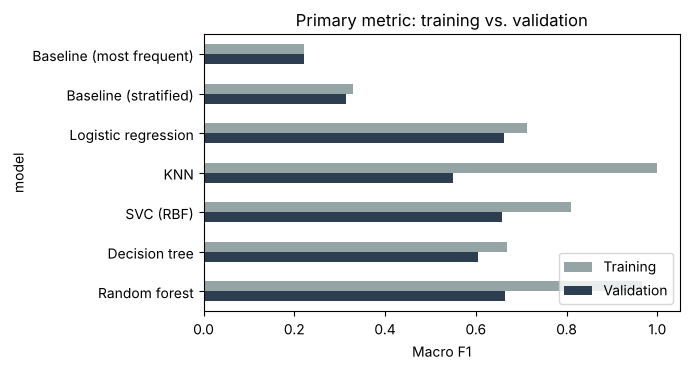

In [14]:
r = res.set_index("model")
ax = r[["train_macro_F1", "val_macro_F1"]].plot.barh(figsize=(7, 3.8), color=["#95a5a6", "#2c3e50"])
ax.set_xlabel("Macro F1"); ax.set_xlim(0, 1.05); ax.invert_yaxis(); ax.legend(["Training", "Validation"], loc="lower right")
ax.set_title("Primary metric: training vs. validation")
plt.tight_layout(); plt.savefig("figures/f1_train_val.png", dpi=150); plt.show()

### 7.2 Confusion matrices (validation)

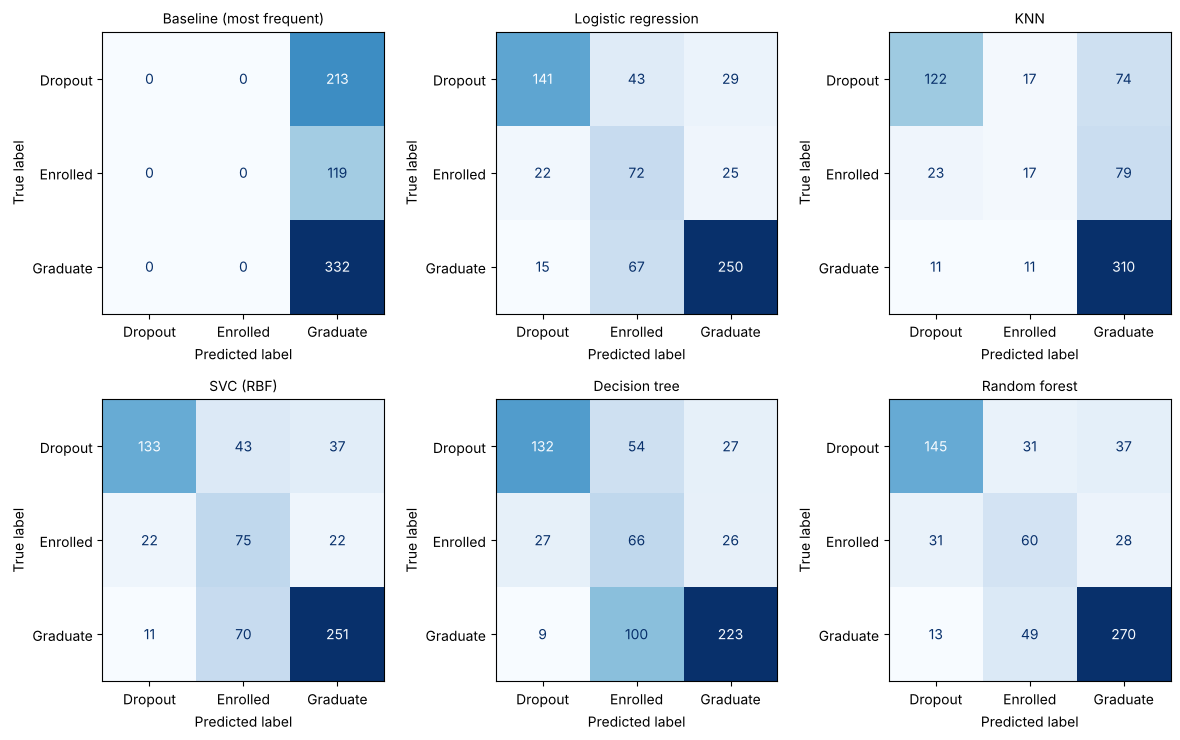

In [15]:
labels = ["Dropout", "Enrolled", "Graduate"]
show = ["Baseline (most frequent)", "Logistic regression", "KNN", "SVC (RBF)", "Decision tree", "Random forest"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, name in zip(axes.ravel(), show):
    ConfusionMatrixDisplay(confusion_matrix(y_val, fitted[name][1], labels=labels), display_labels=labels).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", dpi=150); plt.show()

### 7.3 Per-class report of the two best models (validation)

In [16]:
best2 = res[~res.model.str.startswith("Baseline")].nlargest(2, "val_macro_F1").model.tolist()
for name in best2:
    print(f"===== {name} =====")
    print(classification_report(y_val, fitted[name][1], digits=3))

===== Random forest =====
              precision    recall  f1-score   support

     Dropout      0.767     0.681     0.721       213
    Enrolled      0.429     0.504     0.463       119
    Graduate      0.806     0.813     0.810       332

    accuracy                          0.715       664
   macro avg      0.667     0.666     0.665       664
weighted avg      0.726     0.715     0.719       664

===== Logistic regression =====
              precision    recall  f1-score   support

     Dropout      0.792     0.662     0.721       213
    Enrolled      0.396     0.605     0.478       119
    Graduate      0.822     0.753     0.786       332

    accuracy                          0.697       664
   macro avg      0.670     0.673     0.662       664
weighted avg      0.736     0.697     0.710       664



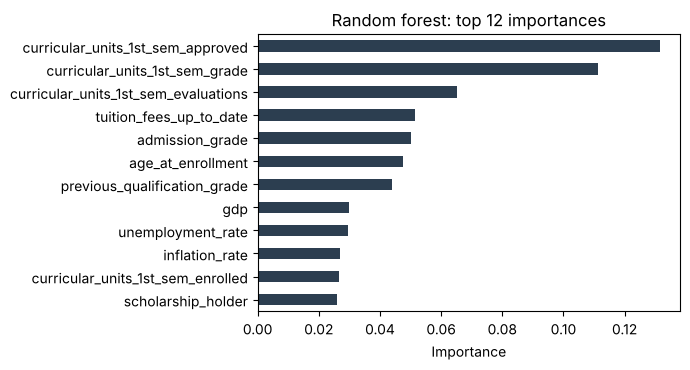

In [17]:
rf = fitted["Random forest"][0]
names = [n.split("__", 1)[1] for n in rf.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(12)
ax = imp[::-1].plot.barh(figsize=(7, 3.8), color="#2c3e50")
ax.set_title("Random forest: top 12 importances"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.savefig("figures/rf_importances.png", dpi=150); plt.show()

## 8. Conclusions

**Comparison with the baseline.** The `most_frequent` baseline reaches 50 % accuracy but a macro F1 of only 0.22, because it never predicts *Dropout* or *Enrolled*; the `stratified` baseline reaches 0.31. All five families beat both references clearly. The three best models are very close in validation macro F1: **random forest 0.665**, **logistic regression 0.662** and SVC 0.657, followed by the decision tree (0.605) and KNN (0.549).

**Overfitting.** KNN with distance weights reproduces the training set perfectly (train F1 = 1.00, gap 0.45) and generalises worst; it also rarely predicts *Enrolled* (45 of 664 predictions). The random forest also fits the training data almost perfectly (0.97, gap 0.30), although its validation score is still the best. Logistic regression (gap 0.05) and the depth-limited tree (gap 0.06) are the most stable; SVC is in between (gap 0.15).

**Per class.** *Graduate* (F1 ≈ 0.79–0.81) and *Dropout* (F1 ≈ 0.72) are recognised reasonably well; *Enrolled* is the weak class (F1 ≈ 0.46–0.48), and most of the errors are confusions between *Enrolled* and the other two classes. This is expected: an enrolled student who is behind schedule looks like a future dropout or a slow graduate after only one semester. The most important variables for the forest are courses passed and average grade in the 1st semester, number of evaluations, tuition fees up to date, admission grade and age. These are associations, not causes.

**Two finalists for Part 2.**
1. **Random forest** — best validation macro F1 (0.665) and best recall for *Dropout* (0.68), the class the support office cares about most. Its overfitting suggests that tuning `min_samples_leaf`, `max_depth` and `max_features` can help.
2. **Logistic regression** — practically the same macro F1 (0.662) with the smallest train–validation gap, very low training cost and interpretable coefficients for the support office. We prefer it over SVC (0.657) because SVC is not better, overfits more and is harder to explain.

The differences among the three best models (≤ 0.008 in macro F1 on 664 validation students) are smaller than the expected sampling noise, so the choice will be confirmed with cross-validation in Part 2.

**Limitations.**
- A single validation set of 664 students: estimates have noticeable variance, and the ranking of the top three models could change with another split.
- The *Enrolled* class is small (18 %) and intrinsically ambiguous at the end of the 1st semester; no configuration reaches an F1 above 0.48 for it.
- About 4 % of students have 0 courses enrolled in the 1st semester but many of them graduate, so the most informative variables are uninformative for them.
- The data come from one Portuguese institution (cohorts 2008/09–2018/19); the macroeconomic variables take only a few values and the model may not transfer to other universities (for example, a Mexican one) without retraining.
- Only one configuration per family was tried, so the comparison measures *initial* configurations, not the best possible version of each family.

**Plan for Part 2.** Merge training and validation into a development set and use **stratified 5-fold cross-validation** (`StratifiedKFold`, `shuffle=True`, `random_state=42`) with macro F1 for the baseline and the two finalists. Tune the random forest with `RandomizedSearchCV` (`n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`) and logistic regression with `GridSearchCV` (`C` on a log scale, L1/L2 penalty). As additional analysis we plan **errors and decisions**: compare at least three decision rules on out-of-fold probabilities that give more priority to detecting *Dropout* (a missed dropout is more costly than an extra tutoring call). Then train the selected solution on the full development set and evaluate it, together with the baseline, on the reserved test set only once.

---
**References.** Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), 146. https://doi.org/10.3390/data7110146 · Pedregosa et al. (2011). Scikit-learn: Machine learning in Python. *JMLR, 12*, 2825–2830.

**Use of AI assistants.** *(Fill in: what you used it for, e.g. drafting code and text, and how the team verified it — re-running the notebook, checking every number against the outputs, reviewing each decision.)*